# Example 15.2 – Ziegler-Nichols Tuning
**Chapter 15 – PID Control Applied to Four-Bar Mechanisms**

In this section, the ultimate gain $K_u$ and ultimate period $T_u$ parameters are experimentally identified, and then the classic Ziegler-Nichols (ZN) tuning rules are applied.

In [ ]:
from numpy import *
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid

## Generic PID Simulation Function

In [ ]:
from numba import njit

@njit
def sim_pid_zn(Kp, Ki, Kd, t_end=8.0, dt=0.005, I=0.05, b=0.05):
    t = arange(0, t_end, dt)
    n = len(t)
    theta = zeros(n)
    omega = zeros(n)

    e_int = 0.0
    e_prev = 0.0
    ref = pi / 3

    th = 0.0
    om = 0.0

    for k in range(1, n):
        e = ref - th
        e_int += e * dt
        de = (e - e_prev) / dt

        u = Kp * e + Ki * e_int + Kd * de
        alpha = (u - b * om) / I

        om += alpha * dt
        th += om * dt

        omega[k] = om
        theta[k] = th
        e_prev = e

    return t, theta

## Step 1: Sustained Oscillation ($K_i = K_d = 0$, $K_p \to K_u$)

In [ ]:
Ku = 12.0; Tu = 0.95  # experimentally identified
t_osc, th_osc = sim_pid_zn(Ku, 0, 0)
print(f'Ku={Ku}, Tu≈{Tu} s')

Ku=12.0, Tu≈0.95 s


## Step 2: Classic Ziegler-Nichols Rules

In [ ]:
Ku = 12.0
Tu = 0.95

Kp_zn = 0.6 * Ku
Ki_zn = Kp_zn / (Tu / 1.2)
Kd_zn = Kp_zn * (Tu / 8.0)
print(f'ZN → Kp={Kp_zn:.2f}, Ki={Ki_zn:.2f}, Kd={Kd_zn:.3f}')
t_zn, th_zn = sim_pid_zn(Kp_zn, Ki_zn, Kd_zn)
e = 60.0 - degrees(th_zn)
ise = trapezoid(e**2, t_zn)
overshoot = (degrees(th_zn).max() - 60.0) / 60.0 * 100.0
print(f'ISE = {ise:.2f}  |  Overshoot = {overshoot:.1f}%')

ZN → Kp=7.20, Ki=9.09, Kd=0.855
ISE = 102.86  |  Overshoot = 20.4%


## Results Visualization

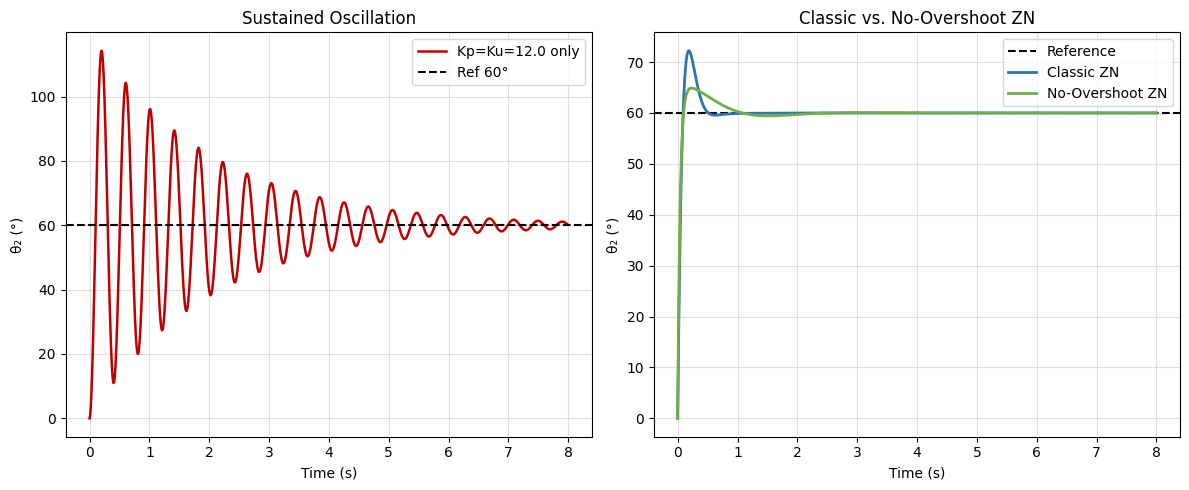

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(t_osc, degrees(th_osc), color='#C00000', lw=1.8, label=f'Kp=Ku={Ku} only')
axes[0].axhline(60, color='k', ls='--', lw=1.5, label='Ref 60°')
axes[0].set_title('Sustained Oscillation'); axes[0].legend(); axes[0].grid(alpha=0.4)
axes[0].set_xlabel('Time (s)'); axes[0].set_ylabel('θ₂ (°)')

Kp_no = 0.33*Ku; Ki_no = Kp_no/(Tu/2); Kd_no = Kp_no*(Tu/3)
t_no, th_no = sim_pid_zn(Kp_no, Ki_no, Kd_no)
axes[1].axhline(60, color='k', ls='--', lw=1.5, label='Reference')
axes[1].plot(t_zn, degrees(th_zn), color='#2E75B6', lw=2, label='Classic ZN')
axes[1].plot(t_no, degrees(th_no), color='#70AD47', lw=2, label='No-Overshoot ZN')
axes[1].set_title('Classic vs. No-Overshoot ZN'); axes[1].legend(); axes[1].grid(alpha=0.4)
axes[1].set_xlabel('Time (s)'); axes[1].set_ylabel('θ₂ (°)')
plt.tight_layout(); plt.show()

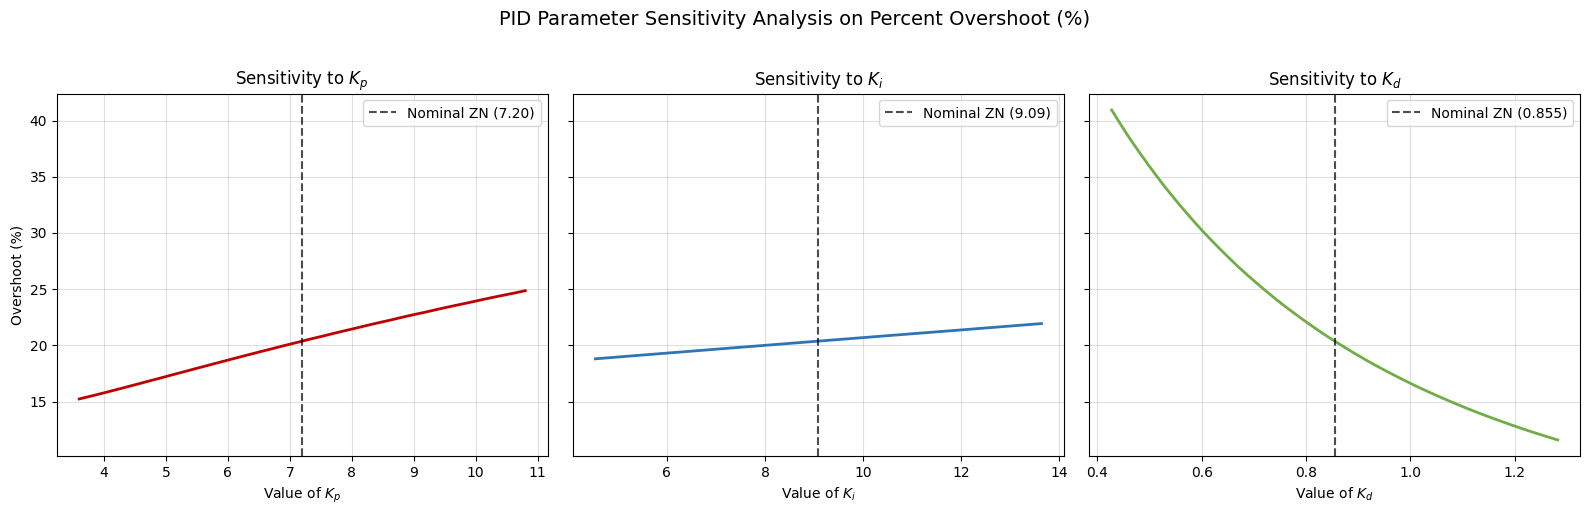

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Nominal Ziegler-Nichols parameters
Kp_nominal = 7.20
Ki_nominal = 9.09
Kd_nominal = 0.855

# Safely calculate percent overshoot
def calculate_overshoot(Kp, Ki, Kd):
    _, th = sim_pid_zn(Kp, Ki, Kd)
    max_deg = np.degrees(th).max()
    overshoot = (max_deg - 60.0) / 60.0 * 100.0
    # Prevent negative overshoot values
    return np.maximum(0.0, float(overshoot))

# Ranges of variation (±50% relative to nominal value)
variation = np.linspace(0.5, 1.5, 50)

overshoots_kp = [calculate_overshoot(Kp_nominal * v, Ki_nominal, Kd_nominal) for v in variation]
overshoots_ki = [calculate_overshoot(Kp_nominal, Ki_nominal * v, Kd_nominal) for v in variation]
overshoots_kd = [calculate_overshoot(Kp_nominal, Ki_nominal, Kd_nominal * v) for v in variation]

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

# Sensitivity to Kp
axes[0].plot(variation * Kp_nominal, overshoots_kp, color='#C00000', lw=2)
axes[0].axvline(Kp_nominal, color='k', ls='--', alpha=0.7, label=f'Nominal ZN ({Kp_nominal:.2f})')
axes[0].set_title('Sensitivity to $K_p$')
axes[0].set_xlabel('Value of $K_p$')
axes[0].set_ylabel('Overshoot (%)')
axes[0].grid(alpha=0.4)
axes[0].legend()

# Sensitivity to Ki
axes[1].plot(variation * Ki_nominal, overshoots_ki, color='#2E75B6', lw=2)
axes[1].axvline(Ki_nominal, color='k', ls='--', alpha=0.7, label=f'Nominal ZN ({Ki_nominal:.2f})')
axes[1].set_title('Sensitivity to $K_i$')
axes[1].set_xlabel('Value of $K_i$')
axes[1].grid(alpha=0.4)
axes[1].legend()

# Sensitivity to Kd
axes[2].plot(variation * Kd_nominal, overshoots_kd, color='#70AD47', lw=2)
axes[2].axvline(Kd_nominal, color='k', ls='--', alpha=0.7, label=f'Nominal ZN ({Kd_nominal:.3f})')
axes[2].set_title('Sensitivity to $K_d$')
axes[2].set_xlabel('Value of $K_d$')
axes[2].grid(alpha=0.4)
axes[2].legend()

plt.suptitle('PID Parameter Sensitivity Analysis on Percent Overshoot (%)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()